# Data Science Project - Phase 1: Data Collection
**The Context Gap**
Mohammad Qasim Khalaf Alsamarrae

In this notebook I collect the data for my project from three VizWiz datasets:
- VQA: questions asked by blind people about their photos, with 10 answers each
- Quality Issues: problems in each photo (blur, dark, framing...)
- Captions: 5 human descriptions for each photo

I use the validation split of all three.

## Download the data

In [29]:
!wget -nc -q https://vizwiz.cs.colorado.edu/VizWiz_final/vqa_data/Annotations.zip -O vqa.zip
!wget -nc -q https://vizwiz.cs.colorado.edu/VizWiz_final/image_quality/annotations.zip -O quality.zip
!wget -nc -q https://vizwiz.cs.colorado.edu/VizWiz_final/caption/annotations.zip -O captions.zip

!unzip -j -o -q vqa.zip -d vqa
!unzip -j -o -q quality.zip -d quality
!unzip -j -o -q captions.zip -d captions

In [30]:
# Import Pandas and numpy
import numpy as np
import pandas as pd

## 1. VQA dataset (questions and answers)

In [31]:
# the files are json not csv, so i use read_json
vqa = pd.read_json("vqa/val.json")
vqa.head()

,image,question,answers,answer_type,answerable
0,VizWiz_val_00000000.jpg,Ok. There is another picture I hope it is a be...,"[{'answer': 'unanswerable', 'answer_confidence...",unanswerable,0
1,VizWiz_val_00000001.jpg,Can you tell me what this medicine is please?,"[{'answer': 'no', 'answer_confidence': 'yes'},...",other,1
2,VizWiz_val_00000002.jpg,What is the title of this book?,"[{'answer': 'dog years', 'answer_confidence': ...",other,1
3,VizWiz_val_00000003.jpg,Which one is the blue one?,"[{'answer': 'right', 'answer_confidence': 'yes...",other,1
4,VizWiz_val_00000004.jpg,What does the arrow say?,"[{'answer': 'unanswerable', 'answer_confidence...",unanswerable,0


In [32]:
vqa.shape

(4319, 5)

In [33]:
vqa.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4319 entries, 0 to 4318
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   image        4319 non-null   object
 1   question     4319 non-null   object
 2   answers      4319 non-null   object
 3   answer_type  4319 non-null   object
 4   answerable   4319 non-null   int64 
dtypes: int64(1), object(4)
memory usage: 168.8+ KB


In [34]:
# one row: the question and its 10 answers
vqa.loc[0, "question"]

'Ok. There is another picture I hope it is a better one.'

In [35]:
vqa.loc[0, "answers"]

[{'answer': 'unanswerable', 'answer_confidence': 'yes'},
 {'answer': 'unanswerable', 'answer_confidence': 'yes'},
 {'answer': 'unanswerable', 'answer_confidence': 'yes'},
 {'answer': 'unanswerable', 'answer_confidence': 'yes'},
 {'answer': 'unanswerable', 'answer_confidence': 'maybe'},
 {'answer': 'unanswerable', 'answer_confidence': 'yes'},
 {'answer': 'unanswerable', 'answer_confidence': 'yes'},
 {'answer': 'unanswerable', 'answer_confidence': 'no'},
 {'answer': 'cannot repair this computer automatically',
  'answer_confidence': 'maybe'},
 {'answer': 'blank screen', 'answer_confidence': 'yes'}]

In [36]:
# check empty values
vqa.isnull().sum()

,0
image,0
question,0
answers,0
answer_type,0
answerable,0


In [37]:
# check duplicated rows (only image and question, answers is a list)
vqa.duplicated(subset=["image", "question"]).sum()

np.int64(0)

In [38]:
# 1 = answerable, 0 = unanswerable
vqa["answerable"].value_counts()

,count
answerable,
1,2934
0,1385


In [39]:
# in percent
vqa["answerable"].value_counts(normalize=True) * 100

,proportion
answerable,
1,67.932392
0,32.067608


In [40]:
vqa["answer_type"].value_counts()

,count
answer_type,
other,2691
unanswerable,1385
yes/no,195
number,48


## 2. Quality issues dataset

In [41]:
quality = pd.read_json("quality/val.json")
quality.head()

,flaws,image,unrecognizable
0,"{'FRM': 2, 'BLR': 0, 'DRK': 0, 'BRT': 0, 'OBS'...",VizWiz_val_00002854.jpg,0
1,"{'FRM': 0, 'BLR': 0, 'DRK': 0, 'BRT': 0, 'OBS'...",VizWiz_val_00001607.jpg,0
2,"{'FRM': 0, 'BLR': 3, 'DRK': 0, 'BRT': 0, 'OBS'...",VizWiz_val_00005141.jpg,1
3,"{'FRM': 4, 'BLR': 5, 'DRK': 0, 'BRT': 0, 'OBS'...",VizWiz_val_00000516.jpg,0
4,"{'FRM': 3, 'BLR': 0, 'DRK': 0, 'BRT': 0, 'OBS'...",VizWiz_val_00007258.jpg,0


In [42]:
# flaws is a dictionary in one column, json_normalize splits it into columns
flaws = pd.json_normalize(quality["flaws"])
quality = pd.concat([quality.drop(columns="flaws"), flaws], axis=1)
quality.head()

,image,unrecognizable,FRM,BLR,DRK,BRT,OBS,OTH,NON,ROT
0,VizWiz_val_00002854.jpg,0,2,0,0,0,1,0,0,5
1,VizWiz_val_00001607.jpg,0,0,0,0,0,0,0,5,0
2,VizWiz_val_00005141.jpg,1,0,3,0,0,0,0,2,1
3,VizWiz_val_00000516.jpg,0,4,5,0,0,0,0,0,0
4,VizWiz_val_00007258.jpg,0,3,0,0,0,0,0,2,0


Each number = how many of the 5 workers saw the problem.
BLR = blur, DRK = dark, BRT = too bright, FRM = bad framing, OBS = blocked, ROT = rotated, OTH = other, NON = no problem

In [43]:
quality.shape

(7750, 10)

In [44]:
quality.describe()

,unrecognizable,FRM,BLR,DRK,BRT,OBS,OTH,NON,ROT
count,7750.000000,7750.000000,7750.000000,7750.000000,7750.000000,7750.000000,7750.000000,7750.000000,7750.000000
mean,0.666710,1.921935,1.610839,0.310194,0.293290,0.198323,0.090581,1.723871,0.625419
std,1.218968,1.508259,1.711186,0.766297,0.722261,0.578598,0.324588,1.578058,1.183052
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
75%,1.000000,3.000000,3.000000,0.000000,0.000000,0.000000,0.000000,3.000000,1.000000
max,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,4.000000,5.000000,5.000000


In [45]:
quality.isnull().sum()

,0
image,0
unrecognizable,0
FRM,0
BLR,0
DRK,0
BRT,0
OBS,0
OTH,0
NON,0
ROT,0


In [46]:
# a problem counts if 3 or more of the 5 workers saw it
problems = ["BLR", "DRK", "BRT", "FRM", "OBS", "ROT", "OTH", "NON"]
percent = (quality[problems] >= 3).mean() * 100
percent.sort_values(ascending=False).round(1)

,0
FRM,36.5
BLR,29.9
NON,29.4
ROT,10.9
DRK,2.8
BRT,2.6
OBS,1.5
OTH,0.1


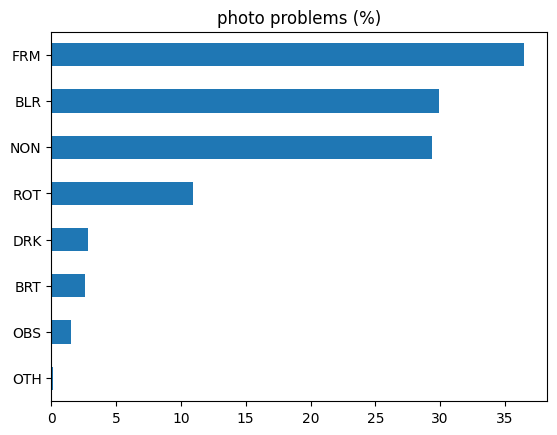

In [47]:
percent.sort_values().plot(kind="barh", title="photo problems (%)");

## 3. Captions dataset

In [48]:
# this file has two parts: images and annotations (the captions)
cap = pd.read_json("captions/val.json", typ="series")
cap_images = pd.DataFrame(cap["images"])
captions = pd.DataFrame(cap["annotations"])
cap_images.head()

,file_name,vizwiz_url,id,text_detected
0,VizWiz_val_00000000.jpg,https://ivc.ischool.utexas.edu/VizWiz_visualiz...,23431,True
1,VizWiz_val_00000001.jpg,https://ivc.ischool.utexas.edu/VizWiz_visualiz...,23432,True
2,VizWiz_val_00000002.jpg,https://ivc.ischool.utexas.edu/VizWiz_visualiz...,23433,True
3,VizWiz_val_00000003.jpg,https://ivc.ischool.utexas.edu/VizWiz_visualiz...,23434,True
4,VizWiz_val_00000004.jpg,https://ivc.ischool.utexas.edu/VizWiz_visualiz...,23435,True


In [49]:
captions.head()

,caption,image_id,is_precanned,is_rejected,id,text_detected
0,A computer screen shows a repair prompt on the...,23431,False,False,117155,True
1,a computer screen with a repair automatically ...,23431,False,False,117156,True
2,partial computer screen showing the need of re...,23431,False,False,117157,True
3,Part of a computer monitor showing a computer ...,23431,False,False,117158,True
4,The top of a laptop with a blue background and...,23431,False,False,117159,True


In [50]:
print(cap_images.shape)
print(captions.shape)

(7750, 4)
(38750, 6)


In [51]:
captions.isnull().sum()

,0
caption,0
image_id,0
is_precanned,0
is_rejected,0
id,0
text_detected,0


## 4. Linking the three datasets
All three use the image file name, so I check how many questions are found in the other two datasets.

In [52]:
# isin checks if each image is found in the other table
in_quality = vqa["image"].isin(quality["image"])
in_captions = vqa["image"].isin(cap_images["file_name"])

print("questions:", len(vqa))
print("found in quality:", in_quality.sum())
print("found in captions:", in_captions.sum())
print("found in both:", (in_quality & in_captions).sum())

questions: 4319
found in quality: 4319
found in captions: 4319
found in both: 4319


In [53]:
# photos with text in them (only the photos that have questions)
my_photos = cap_images[cap_images["file_name"].isin(vqa["image"])]
my_photos["text_detected"].mean() * 100

np.float64(70.06251447094235)

## 5. A look at the questions

In [54]:
# number of words in each question
vqa["words"] = vqa["question"].str.split().str.len()
vqa["words"].describe()

,words
count,4319.000000
mean,7.169484
std,5.822843
min,2.000000
25%,4.000000
50%,5.000000
75%,8.000000
max,49.000000


In [55]:
# the first two words of each question
vqa["start"] = vqa["question"].str.lower().str.split().str[:2].str.join(" ")
vqa["start"].value_counts().head(10)

,count
start,
what is,1393
can you,320
what does,294
what color,291
what kind,208
is this,99
what's in,64
what flavor,53
what are,48


## Save

In [56]:
vqa.to_csv("vqa_raw.csv", index=False)
quality.to_csv("quality_raw.csv", index=False)
captions.to_csv("captions_raw.csv", index=False)
cap_images.to_csv("caption_images_raw.csv", index=False)

## Notes
- All 4,319 questions are found in both the quality and captions data, so nothing is missing.
- 32.1% of the questions could not be answered.
- The most common problem is bad framing (36.5%), then blur (29.9%). Only 29.4% of photos have no problem.
- 70.1% of the photos have text in them.
- Almost a third of the questions start with "what is".

Next step: cleaning the data and merging it into one table.